# Intro to Pandas

## *Workshop 2*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W02.%20Pandas.ipynb)

In this workshop we get used to working with data imported from external files: we load it with *pandas*, select the bits we're interested in, clean it, and graph it.

### Aims

- Import data into Python with pandas
- Access specific rows, columns and cells
- Plot the data, with labelled axes
- Find and fix data that has been read in as text
- Filter by value
- Reshape data from **wide** to **long** format

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)

## Introduction

We are going to work with some UK income data: income by **percentile**, from the Family Resources Survey 2010-11, collated by the Institute for Fiscal Studies ([where do you fit in?](https://ifs.org.uk/tools_and_resources/where_do_you_fit_in)). The IFS **equivalises** incomes: it adjusts them for household size, because a couple needs more than a single person but not twice as much ([equivalisation](https://en.wikipedia.org/wiki/Equivalisation)).

The IFS is quoted in UK Government documents, so we can have some trust in its accuracy. If we were publishing research on this, that wouldn't be good enough: we'd want to understand, and ideally reproduce, its methodology rather than just trust it.

## Loading the data

`read_csv` can read straight from a URL. We tell pandas to use the first column (the percentile) as the index, which makes life easier.

In [3]:
import pandas as pd

income = pd.read_csv("https://s3.eu-west-2.amazonaws.com/qm2/wk2/incomes.csv", index_col=0)
income.head()

,"Net equivalised household income in 2010-11, week","Childless couple, annual income","Couple, two children under 14","Couple, three children under 14",Couple with one child under 14,Couple with two children aged 15 to 18,"Couple, two children under 14 plus dependent adult",Single adult,"Lone parent, one child under 14","Lone parent, two children under 14","Lone parent, two children aged 15-18",ANNOTATIONS,1979 to 1996-97,1996-97 to 2009-10,1996-97 to 2010-11
Percentile Point,,,,,,,,,,,,,,,
1,33.50,"1,746.92","2,445.69","2,795.08","2,096.31","2,899.89","3,022.18","1,170.44","1,519.82","1,869.21","2,323.41",NaN,NaN,NaN,NaN
2,98.60,"5,141.01","7,197.41","8,225.61","6,169.21","8,534.07","8,893.95","3,444.48","4,472.68","5,500.88","6,837.54",NaN,-0.20%,-1.30%,-0.50%
3,128.56,"6,703.11","9,384.36","10,724.98","8,043.74","11,127.17","11,596.39","4,491.09","5,831.71","7,172.33","8,915.14",NaN,0.40%,0.10%,0.10%
4,151.05,"7,875.75","11,026.05","12,601.20","9,450.90","13,073.75","13,625.05","5,276.75","6,851.90","8,427.05","10,474.75",NaN,0.50%,0.80%,0.60%
5,166.32,"8,671.91","12,140.68","13,875.06","10,406.30","14,395.38","15,002.41","5,810.18","7,544.57","9,278.95","11,533.65",NaN,0.70%,1.00%,0.90%


The percentile tells us how people on that income rank. The final row, 99 (really 99 < n ≤ 100), tells us how much "the 1%" earn:

In [ ]:
income.tail()

,"Net equivalised household income in 2010-11, week","Childless couple, annual income","Couple, two children under 14","Couple, three children under 14",Couple with one child under 14,Couple with two children aged 15 to 18,"Couple, two children under 14 plus dependent adult",Single adult,"Lone parent, one child under 14","Lone parent, two children under 14","Lone parent, two children aged 15-18",ANNOTATIONS,1979 to 1996-97,1996-97 to 2009-10,1996-97 to 2010-11
Percentile Point,,,,,,,,,,,,,,,
95,1075.73,"56,088.56","78,523.99","89,741.70","67,306.27","93,107.01","97,033.21","37,579.34","48,797.05","60,014.76","74,597.79",NaN,2.90%,2.00%,1.30%
96,1174.48,"61,237.18","85,732.05","97,979.49","73,484.61","101,653.72","105,940.32","41,028.91","53,276.35","65,523.78","81,445.45",NaN,3.00%,2.00%,1.40%
97,1302.74,"67,925.07","95,095.10","108,680.12","81,510.09","112,755.62","117,510.37","45,509.80","59,094.81","72,679.83","90,340.35",NaN,3.20%,2.20%,1.60%
98,1523.31,"79,425.23","111,195.32","127,080.36","95,310.27","131,845.88","137,405.64","53,214.90","69,099.95","84,984.99","105,635.55",NaN,3.20%,2.70%,1.70%
99,2090.35,"108,990.74","152,587.04","174,385.19","130,788.89","180,924.64","188,553.99","73,023.80","94,821.95","116,620.10","144,957.69",NaN,NaN,NaN,NaN


The 1% take home, on average, about £2,000 a week. How does that compare with the 90th percentile? We can access a **row** with `.loc[row label]`; because our index is the percentile, we can just read it off:

In [ ]:
income.loc[90]

We can also select a range of rows with the colon notation. With `.loc`, the end point is *included*:

In [ ]:
income.loc[90:95]

## Accessing parts of a dataframe

Columns are referenced by **name**, in square brackets:

In [4]:
weekly = "Net equivalised household income in 2010-11, week"
income[weekly]

,"Net equivalised household income in 2010-11, week"
Percentile Point,
1,33.50
2,98.60
3,128.56
4,151.05
5,166.32
...,...
95,1075.73
96,1174.48
97,1302.74


To get a single **cell**, give `.loc` both the row and the column:

In [5]:
income.loc[90, weekly]

np.float64(845.54)

So, to recap:

- a **row**: `income.loc[90]`, or a range `income.loc[90:95]`
- a **column**: `income["column name"]`
- a **cell**: `income.loc[90, "column name"]`

`.iloc[]` does the same by *position* (0, 1, 2, ...) rather than by label; see the [pandas documentation](https://pandas.pydata.org/docs/user_guide/indexing.html).

### Exercise

How do the equivalised incomes of single adults (`"Single adult"`) and childless couples (`"Childless couple, annual income"`) compare? Look at the 1st, 50th and 99th percentiles and summarise what this tells you about the value, or price, of coupling.

In [8]:
import pandas as pd

compare_df = income[["Single adult", "Childless couple, annual income"]].copy()
compare_df = compare_df.replace(",", "", regex=True).astype(float)

comparison = compare_df.loc[[1, 50, 99]]
display(comparison)

,Single adult,"Childless couple, annual income"
Percentile Point,,
1,1170.44,1746.92
50,14627.95,21832.75
99,73023.80,108990.74


## Examining the distribution

The 90th percentile earns less than half of what the top percentile does: if your household takes home over £800 a week, you're in the top 10%. Let's plot the whole curve:

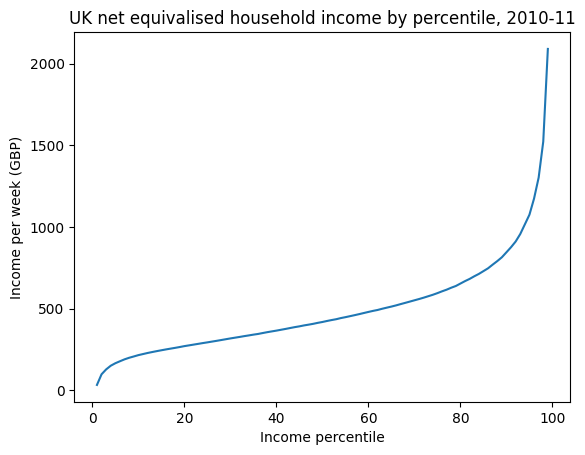

In [10]:
import matplotlib.pyplot as plt

income[weekly].plot()
plt.title("UK net equivalised household income by percentile, 2010-11")
plt.xlabel("Income percentile")
plt.ylabel("Income per week (GBP)")
plt.show()

The curve is roughly linear in the middle, but rises steeply at the top.

### Exercise: means

Where does the mean appear here? Draw a horizontal line for the **mean** with `plt.axhline`, and one for the **median** on the same graph. Which is higher, and why? What does the median mean in this context?

Hint: last week we used `axvline` to draw vertical lines; `axhline` draws horizontal ones.

Mean Income: £490.04 per week
Median Income: £418.73 per week


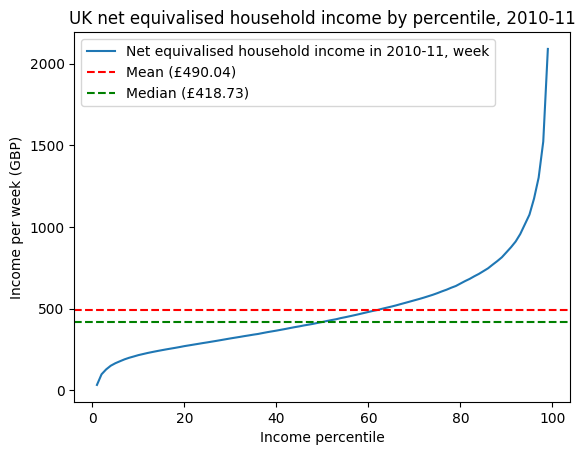

In [18]:
import matplotlib.pyplot as plt

mean_income = income[weekly].mean()
median_income = income[weekly].median()

print(f"Mean Income: £{mean_income:.2f} per week")
print(f"Median Income: £{median_income:.2f} per week")

income[weekly].plot()

plt.axhline(mean_income, color='red', linestyle='--', label=f'Mean (£{mean_income:.2f})')
plt.axhline(median_income, color='green', linestyle='--', label=f'Median (£{median_income:.2f})')

plt.title("UK net equivalised household income by percentile, 2010-11")
plt.xlabel("Income percentile")
plt.ylabel("Income per week (GBP)")
plt.legend()
plt.show()

## Messy data

Earlier we compared single people and couples. Let's plot the whole curve for both groups:

In [14]:
# This is going to throw an error
income[["Single adult", "Childless couple, annual income"]].plot()

TypeError: no numeric data to plot

An error! When you see one, read the **last line** first: here it says there is "no numeric data to plot", which is odd, because we can see the numbers. `.dtypes` shows what type pandas thinks each column is:

In [ ]:
income.dtypes

Net equivalised household income in 2010-11, week     float64
Childless couple, annual income                           str
Couple, two children under 14                             str
Couple, three children under 14                           str
Couple with one child under 14                            str
Couple with two children aged 15 to 18                    str
Couple, two children under 14 plus dependent adult        str
Single adult                                              str
Lone parent, one child under 14                           str
Lone parent, two children under 14                        str
Lone parent, two children aged 15-18                      str
ANNOTATIONS                                               str
1979 to 1996-97                                           str
1996-97 to 2009-10                                        str
1996-97 to 2010-11                                        str
dtype: object

Only the weekly column is a number (`float64`). Let's look at one of the other values:

In [ ]:
income.loc[50, "Single adult"]

'14,627.95'

`'14,627.95'` is a piece of **text** (a string), not a number. The commas make it easier for people to read, but they confuse software. Missing values are sometimes written as `-`, which causes the same problem. In general, some detective work is needed to figure out what's wrong with a data file: looking at the raw values, or opening the file in a text editor, is often the quickest way.

### Example: cleaning data

We'll make a new dataframe with just the two columns we're interested in, remove the commas with `.replace()`, and convert the result to numbers with `.astype(float)`:

In [15]:
clean = income[["Childless couple, annual income", "Couple, two children under 14"]]
clean = clean.replace(",", "", regex=True).astype(float)
clean.head()

,"Childless couple, annual income","Couple, two children under 14"
Percentile Point,,
1,1746.92,2445.69
2,5141.01,7197.41
3,6703.11,9384.36
4,7875.75,11026.05
5,8671.91,12140.68


(**Extension:** `regex` stands for *regular expression*, a powerful way of searching and replacing text. It's beyond the scope of this class, but worth looking into.)

Now the plot works:

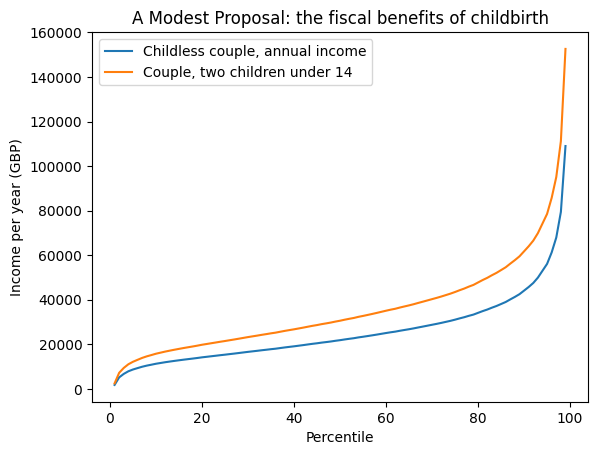

In [16]:
clean.plot()
plt.title("A Modest Proposal: the fiscal benefits of childbirth")
plt.xlabel("Percentile")
plt.ylabel("Income per year (GBP)")
plt.show()

This raises further questions. If the top 20% shows such a sharp increase, is there a similar uptick *within* the 1%? How does the curve break down by gender, education or ethnicity?

### Exercise

Repeat the cleaning and plotting for single adults and childless couples. Comment on the differences.

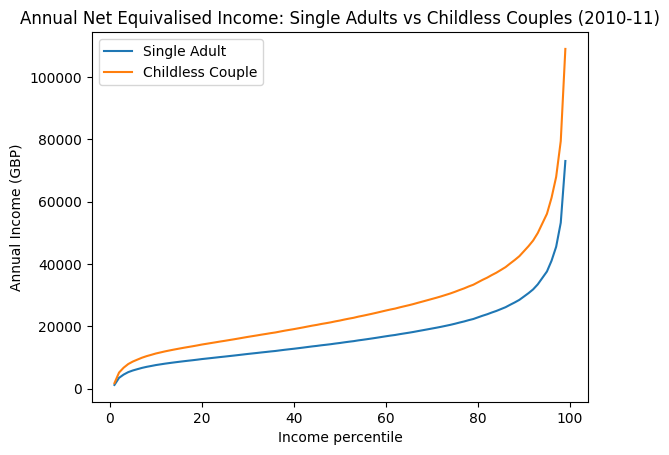

In [20]:
import matplotlib.pyplot as plt

clean_comparison = income[["Single adult", "Childless couple, annual income"]].copy()

clean_comparison = clean_comparison.replace(",", "", regex=True).astype(float)

clean_comparison.plot()
plt.title("Annual Net Equivalised Income: Single Adults vs Childless Couples (2010-11)")
plt.xlabel("Income percentile")
plt.ylabel("Annual Income (GBP)")
plt.legend(["Single Adult", "Childless Couple"])
plt.show()

## Filtering by value

So far we've selected data by its label. What if we want to filter by **value**? For example, all childless couples with a net equivalised income above £50,000 a year:

In [ ]:
clean[clean["Childless couple, annual income"] > 50000]

,"Childless couple, annual income","Couple, two children under 14"
Percentile Point,,
94,52993.38,74190.73
95,56088.56,78523.99
96,61237.18,85732.05
97,67925.07,95095.10
98,79425.23,111195.32
99,108990.74,152587.04


Let's break this down. The condition inside the brackets gives `True` or `False` for every row:

In [ ]:
clean["Childless couple, annual income"] > 50000

Percentile Point
1     False
2     False
3     False
4     False
5     False
      ...  
95     True
96     True
97     True
98     True
99     True
Name: Childless couple, annual income, Length: 99, dtype: bool

Putting it inside `clean[ ]` keeps only the rows where it is `True`. Other comparison operators:

- `==` is equal to (why the double equals?)
- `!=` is not equal to
- `<`, `<=`, `>`, `>=`

### Exercise

On an appropriately labelled graph, plot the incomes of all single adults whose net equivalised income is less than or equal to £10,000 a year. What proportion of the population is this?

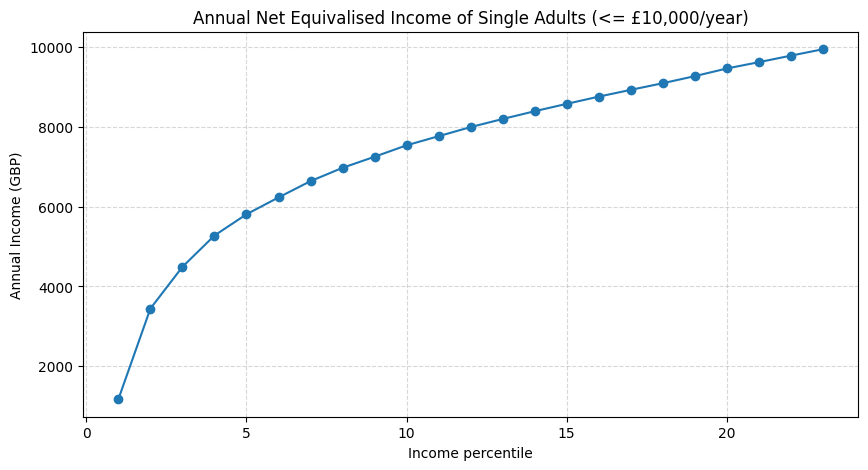

Number of percentiles matching the criteria: 23 out of 99
Proportion of the population: 23.23%


In [22]:
import matplotlib.pyplot as plt
import pandas as pd

single_adult_clean = income['Single adult'].str.replace(',', '', regex=True).astype(float)

filtered_single = single_adult_clean[single_adult_clean <= 10000]

plt.figure(figsize=(10, 5))
filtered_single.plot(marker='o', linestyle='-')
plt.title("Annual Net Equivalised Income of Single Adults (<= £10,000/year)")
plt.xlabel("Income percentile")
plt.ylabel("Annual Income (GBP)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

proportion = (len(filtered_single) / len(single_adult_clean)) * 100
print(f"Number of percentiles matching the criteria: {len(filtered_single)} out of {len(single_adult_clean)}")
print(f"Proportion of the population: {proportion:.2f}%")

## Wide and long data

Data that records the same units (countries, ships, firms) repeatedly over time comes in two layouts:

- **wide**: one row per unit, one column per time period. Compact, and how most published tables look.
- **long**: one row per unit × time period. More repetition, but it's what grouping, plotting and statistics expect.

[Global Fishing Watch](https://globalfishingwatch.org) uses the signals that ships broadcast to estimate where and when vessels are fishing. This file gives **apparent fishing hours** per month for the ten flag states (countries a vessel is registered to) with the most fishing, 2017-2024, in **wide** format:

*Data: Global Fishing Watch, [fishing effort v3](https://globalfishingwatch.org/dataset-and-code-fishing-effort/), CC BY-NC 4.0.*

In [ ]:
fish_wide = pd.read_csv("https://storage.googleapis.com/qm2/2627/w02/fishing_hours_by_flag_wide.csv")
fish_wide.iloc[:, :6]

,flag,2017-01,2017-02,2017-03,2017-04,2017-05
0,CHN,516065.0,491399.0,931656.0,1374245,262149
1,TWN,181201.0,157107.0,164549.0,231917,227847
2,KOR,90687.0,86070.0,104216.0,117044,162617
3,ESP,152648.0,137025.0,177311.0,168193,219950
4,ITA,135206.0,170771.0,205276.0,174239,273744
5,RUS,135968.0,145381.0,174577.0,153922,150192
6,USA,105330.0,119962.0,121349.0,123421,129441
7,JPN,125162.0,104445.0,103993.0,105902,129725
8,FRA,129467.0,118467.0,145698.0,136067,139850
9,VNM,NaN,NaN,NaN,0,152


The column names are **months**, not variables. `melt` turns wide into long: the `id_vars` column stays fixed, and all the other columns are "melted" into two, one for the old column names (`var_name`) and one for the values (`value_name`). We also convert the month text into a real date with `pd.to_datetime`:

In [ ]:
fish = fish_wide.melt(id_vars="flag", var_name="month", value_name="fishing_hours")
fish["month"] = pd.to_datetime(fish["month"])
print(fish_wide.shape, "->", fish.shape)
fish.head()

(10, 97) -> (960, 3)


,flag,month,fishing_hours
0,CHN,2017-01-01,516065.0
1,TWN,2017-01-01,181201.0
2,KOR,2017-01-01,90687.0
3,ESP,2017-01-01,152648.0
4,ITA,2017-01-01,135206.0


In long format, totals per flag per year take one line with `groupby`:

In [ ]:
annual = fish.groupby(["flag", fish["month"].dt.year])["fishing_hours"].sum().unstack()
annual

month,2017,2018,2019,2020,2021,2022,2023,2024
flag,,,,,,,,
CHN,12523458.0,13426537.0,14754795.0,15222077.0,17087644.0,38209963.0,52509582.0,52444468.0
ESP,2388327.0,2437855.0,2541881.0,2439013.0,2476589.0,2577604.0,2497668.0,2460161.0
FRA,1719214.0,1719416.0,1784304.0,1665858.0,1753653.0,1782290.0,1645055.0,1620893.0
ITA,2310364.0,2143833.0,2121469.0,2057772.0,2170930.0,2063244.0,1951247.0,2172731.0
JPN,1592347.0,1781104.0,1799566.0,1881217.0,1962270.0,1997766.0,2171133.0,2293628.0
KOR,1513220.0,1937505.0,2421058.0,2641090.0,2821270.0,4920621.0,5233110.0,5436460.0
RUS,1852637.0,1986392.0,2037356.0,2105435.0,2081188.0,2074647.0,1975143.0,1759197.0
TWN,2818622.0,3606001.0,3933618.0,3635081.0,3564124.0,4758334.0,4826240.0,4727097.0
USA,1561435.0,1731555.0,1745786.0,2088425.0,2207002.0,2146914.0,2099963.0,1982138.0


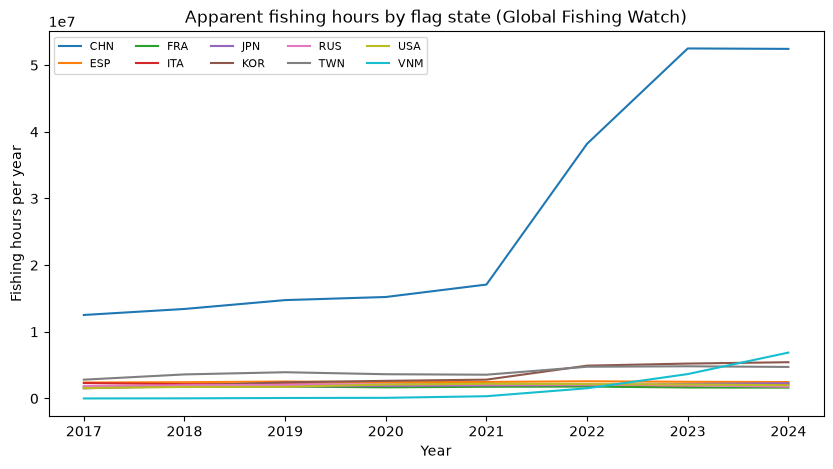

In [ ]:
annual.T.plot()
plt.title("Apparent fishing hours by flag state (Global Fishing Watch)")
plt.xlabel("Year")
plt.ylabel("Fishing hours per year")
plt.legend(ncol=5, fontsize=8)
plt.show()

## Extension: web scraping

So far we've used files that contain all the data we want. Sometimes the data is only in a table on a website. `pd.read_html` finds the HTML tables on a page and returns them as a **list** of dataframes. Let's try the [Netflix Top 10](https://top10.netflix.com/) (it changes every week, so your output will differ):

In [30]:
tables = pd.read_html("https://top10.netflix.com/")
print(len(tables), "table(s) found")
top10 = tables[0]
top10

1 table(s) found


,Ranking,Unnamed: 1,Views,Runtime,Hours Viewed
0,01Animals,1,23800000,1:48,42800000
1,02Doing Life,2,18200000,1:48,32800000
2,03Ice Age,1,11200000,1:23,15500000
3,04Ice Age: Collision Course,4,9300000,1:37,15100000
4,05Ice Age: Dawn of the Dinosaurs,4,8000000,1:35,12700000
5,06Ice Age: The Meltdown,1,7700000,1:33,11900000
6,07UNABOMBER,3,7300000,1:40,12100000
7,08The Widower: 'Til Death Do Us Part,2,7200000,1:32,11000000
8,09Ice Age: Continental Drift,1,6600000,1:31,10000000
9,10The Forever Purge,2,4000000,1:43,6900000


It mostly worked, but one column has no proper name. We can rename it; since it's the second column, we select it with `top10.columns[1]`:

In [ ]:
top10 = top10.rename(columns={top10.columns[1]: "Weeks in Top 10"})
top10

,Ranking,Weeks in Top 10,Views,Runtime,Hours Viewed
0,01Animals,1,23800000,1:48,42800000
1,02Doing Life,2,18200000,1:48,32800000
2,03Ice Age,1,11200000,1:23,15500000
3,04Ice Age: Collision Course,4,9300000,1:37,15100000
4,05Ice Age: Dawn of the Dinosaurs,4,8000000,1:35,12700000
5,06Ice Age: The Meltdown,1,7700000,1:33,11900000
6,07UNABOMBER,3,7300000,1:40,12100000
7,08The Widower: 'Til Death Do Us Part,2,7200000,1:32,11000000
8,09Ice Age: Continental Drift,1,6600000,1:31,10000000
9,10The Forever Purge,2,4000000,1:43,6900000


A nicely formatted dataframe, straight from a website.

> Some sites (Wikipedia included) refuse requests that don't identify themselves. If `read_html(url)` gives `HTTP Error 403: Forbidden`, fetch the page with `requests.get(url, headers={"User-Agent": "BASC0005 student"})` and pass `io.StringIO(response.text)` to `read_html`.

# Assessed Question

The URL below contains a wide table of monthly apparent fishing hours for ten flag states (Global Fishing Watch), in the same layout as the one you reshaped above:

https://oballinger.github.io/BASC0005/data/assessed/w02_fishing_hours_by_flag_wide.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: How many of the ten flag states recorded MORE total fishing hours in 2021 than in 2020?**

Keep a note of your answer: you will enter it in the Problem Set Answers quiz on Moodle in December.

In [26]:
import pandas as pd
import numpy as np

# Load the dataset
url = "https://oballinger.github.io/BASC0005/data/assessed/w02_fishing_hours_by_flag_wide.csv"
df_assessed = pd.read_csv(url)

# Display basic info and first few rows to inspect the structure and any potential corruption
print("Dataset Shape:", df_assessed.shape)
display(df_assessed.head(10))
display(df_assessed.info())

Dataset Shape: (10, 97)


,flag,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,...,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
0,CHN,516065.0,491399.0,931656.0,1374245,262149,305613,393890,1359090,2742886,...,4789041,5504894,1419071,1513525,1515295,4660186,6534814,6828726,6243907,6544762
1,TWN,181201.0,157107.0,164549.0,231917,227847,210907,248714,287478,280934,...,346314,400427,434879,459503,468848,501820,351379,340642,362420,372088
2,KOR,"90,687","86,070","104,216","117,044","162,617","178,586","157,664","149,919","144,196",...,"369,628","421,601","509,530","545,721","474,281","555,153","529,668","537,804","439,176","438,225"
3,ESP,152648.0,137025.0,177311.0,168193,219950,230783,238054,241336,227040,...,171404,217810,244080,254287,270636,241451,200301,188093,193177,166587
4,ITA,135206.0,170771.0,205276.0,174239,273744,287198,272017,195548,123879,...,173562,186129,237289,244841,245379,146198,125272,133804,183039,167405
5,RUS,135968.0,145381.0,174577.0,153922,150192,153760,163325,171055,165744,...,155848,142907,154442,168806,174065,154448,145979,134526,121874,130615
6,USA,105330.0,119962.0,121349.0,123421,129441,149916,174494,167599,135691,...,131852,151536,201061,218350,255751,226752,180772,169164,121035,116173
7,JPN,125162.0,104445.0,103993.0,105902,129725,130546,136784,138518,147522,...,168542,192238,190845,205506,216082,193016,206318,211629,192865,195559
8,FRA,129467.0,118467.0,145698.0,136067,139850,141090,150131,158684,151401,...,144801,141772,148853,135766,141822,137975,120773,160165,139703,116944
9,VNM,NaN,NaN,NaN,0,152,40,332,388,161,...,448095,515868,565537,674810,721780,872637,656228,721391,573725,604286


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 97 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   flag     10 non-null     object
 1   2017-01  9 non-null      object
 2   2017-02  9 non-null      object
 3   2017-03  9 non-null      object
 4   2017-04  10 non-null     object
 5   2017-05  10 non-null     object
 6   2017-06  10 non-null     object
 7   2017-07  10 non-null     object
 8   2017-08  10 non-null     object
 9   2017-09  10 non-null     object
 10  2017-10  10 non-null     object
 11  2017-11  10 non-null     object
 12  2017-12  10 non-null     object
 13  2018-01  10 non-null     object
 14  2018-02  10 non-null     object
 15  2018-03  10 non-null     object
 16  2018-04  10 non-null     object
 17  2018-05  10 non-null     object
 18  2018-06  10 non-null     object
 19  2018-07  10 non-null     object
 20  2018-08  10 non-null     object
 21  2018-09  10 non-null     object
 22  2018-

None

In [31]:
# Clean and reshape the dataset
# Melts all columns except 'flag'
melted_df = df_assessed.melt(id_vars="flag", var_name="month", value_name="fishing_hours")

# Check for any corruption in the 'month' column and 'fishing_hours' values
print("Unique flag values:", melted_df['flag'].unique())

# Convert 'fishing_hours' to numeric, forcing errors to NaN to handle any non-numeric corruption gracefully
melted_df['fishing_hours'] = pd.to_numeric(melted_df['fishing_hours'], errors='coerce')

# Convert 'month' to datetime, forcing errors to NaT to check if any column names were corrupted
melted_df['datetime'] = pd.to_datetime(melted_df['month'], errors='coerce')

# Check if any dates failed to parse
failed_dates = melted_df[melted_df['datetime'].isna()]['month'].unique()
if len(failed_dates) > 0:
    print("Corrupted or unparseable date columns found:", failed_dates)
else:
    print("All month columns successfully parsed to dates.")

# Group by flag state and year to calculate annual sum
melted_df['year'] = melted_df['datetime'].dt.year
annual_totals = melted_df.groupby(['flag', 'year'])['fishing_hours'].sum(min_count=1).unstack()

# Filter for 2020 and 2021 and display the comparison
comparison_df = annual_totals[[2020, 2021]].copy()
comparison_df['More in 2021'] = comparison_df[2021] > comparison_df[2020]

display(comparison_df)
print(f"Number of flags with more fishing hours in 2021 than in 2020: {comparison_df['More in 2021'].sum()}")

Unique flag values: ['CHN' 'TWN' 'KOR' 'ESP' 'ITA' 'RUS' 'USA' 'JPN' 'FRA' 'VNM']
All month columns successfully parsed to dates.


year,2020,2021,More in 2021
flag,,,
CHN,15222077.0,17087644.0,True
ESP,2439013.0,2476589.0,True
FRA,1665858.0,1753653.0,True
ITA,2057772.0,2170930.0,True
JPN,1881217.0,1962270.0,True
KOR,NaN,NaN,False
RUS,2105435.0,2081188.0,False
TWN,3635081.0,3564124.0,False
USA,2088425.0,2207002.0,True


Number of flags with more fishing hours in 2021 than in 2020: 7


In [29]:
# Fix the comma corruption specifically
df_cleaned = df_assessed.copy()
for col in df_cleaned.columns:
    if col != 'flag':
        df_cleaned[col] = df_cleaned[col].astype(str).str.replace(',', '', regex=True)

# Re-melt with the fully cleaned string values
melted_cleaned = df_cleaned.melt(id_vars="flag", var_name="month", value_name="fishing_hours")
melted_cleaned['fishing_hours'] = pd.to_numeric(melted_cleaned['fishing_hours'], errors='coerce')
melted_cleaned['datetime'] = pd.to_datetime(melted_cleaned['month'], errors='coerce')
melted_cleaned['year'] = melted_cleaned['datetime'].dt.year

# Group and sum
annual_clean = melted_cleaned.groupby(['flag', 'year'])['fishing_hours'].sum(min_count=1).unstack()
comparison_clean = annual_clean[[2020, 2021]].copy()
comparison_clean['More in 2021'] = comparison_clean[2021] > comparison_clean[2020]

display(comparison_clean)
print(f"Corrected number of flags with more fishing hours in 2021: {comparison_clean['More in 2021'].sum()}")

year,2020,2021,More in 2021
flag,,,
CHN,15222077.0,17087644.0,True
ESP,2439013.0,2476589.0,True
FRA,1665858.0,1753653.0,True
ITA,2057772.0,2170930.0,True
JPN,1881217.0,1962270.0,True
KOR,2641090.0,2821270.0,True
RUS,2105435.0,2081188.0,False
TWN,3635081.0,3564124.0,False
USA,2088425.0,2207002.0,True


Corrected number of flags with more fishing hours in 2021: 8


## Supplementary: Kaggle exercises

To practise further, work through the [Pandas](https://www.kaggle.com/learn/pandas) course on Kaggle.